In [1]:
from google.colab import files
uploaded = files.upload( )



Saving bahrain_2024_laps_raw.csv to bahrain_2024_laps_raw.csv


In [8]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
data = pd.read_csv("bahrain_2024_laps_raw.csv")
print(f'name of columns:', data.columns.tolist())
data.head(900)

name of columns: ['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']


,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 01:01:37.489000,VER,1,0 days 00:01:37.284000,1.0,1.0,NaN,NaN,NaN,0 days 00:00:41.266000,...,False,Red Bull Racing,0 days 00:59:59.911000,NaN,12,1.0,False,NaN,False,False
1,0 days 01:03:13.785000,VER,1,0 days 00:01:36.296000,2.0,1.0,NaN,NaN,0 days 00:00:30.916000,0 days 00:00:41.661000,...,False,Red Bull Racing,0 days 01:01:37.489000,NaN,1,1.0,False,NaN,False,True
2,0 days 01:04:50.538000,VER,1,0 days 00:01:36.753000,3.0,1.0,NaN,NaN,0 days 00:00:30.999000,0 days 00:00:41.966000,...,False,Red Bull Racing,0 days 01:03:13.785000,NaN,1,1.0,False,NaN,False,True
3,0 days 01:06:27.185000,VER,1,0 days 00:01:36.647000,4.0,1.0,NaN,NaN,0 days 00:00:30.931000,0 days 00:00:41.892000,...,False,Red Bull Racing,0 days 01:04:50.538000,NaN,1,1.0,False,NaN,False,True
4,0 days 01:08:04.358000,VER,1,0 days 00:01:37.173000,5.0,1.0,NaN,NaN,0 days 00:00:31.255000,0 days 00:00:42.056000,...,False,Red Bull Racing,0 days 01:06:27.185000,NaN,1,1.0,False,NaN,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,0 days 02:16:06.978000,HUL,27,0 days 00:01:34.834000,46.0,4.0,NaN,NaN,0 days 00:00:30.170000,0 days 00:00:41.145000,...,False,Haas F1 Team,0 days 02:14:32.144000,NaN,1,17.0,False,NaN,False,True
896,0 days 02:17:42.204000,HUL,27,0 days 00:01:35.226000,47.0,4.0,NaN,NaN,0 days 00:00:30.362000,0 days 00:00:41.251000,...,False,Haas F1 Team,0 days 02:16:06.978000,NaN,1,17.0,False,NaN,False,True
897,0 days 02:19:17.350000,HUL,27,0 days 00:01:35.146000,48.0,4.0,NaN,NaN,0 days 00:00:30.228000,0 days 00:00:41.355000,...,False,Haas F1 Team,0 days 02:17:42.204000,NaN,1,17.0,False,NaN,False,True
898,0 days 02:20:52.844000,HUL,27,0 days 00:01:35.494000,49.0,4.0,NaN,NaN,0 days 00:00:30.323000,0 days 00:00:41.489000,...,False,Haas F1 Team,0 days 02:19:17.350000,NaN,1,17.0,False,NaN,False,True


In [6]:
data.describe()

,DriverNumber,LapNumber,Stint,SpeedI1,SpeedI2,SpeedFL,SpeedST,TyreLife,LapStartDate,TrackStatus,Position
count,1129.000000,1129.000000,1129.000000,1129.000000,1129.000000,1086.000000,1129.000000,1129.000000,0.0,1129.000000,1129.000000
mean,27.352524,28.728078,2.260407,232.797166,254.411869,280.732044,297.123118,10.705934,NaN,1.425155,10.447298
std,23.722384,16.305688,0.825910,3.896779,7.563647,3.479105,19.297776,6.277025,NaN,2.195241,5.764214
min,1.000000,1.000000,1.000000,185.000000,195.000000,244.000000,186.000000,1.000000,NaN,1.000000,1.000000
25%,11.000000,15.000000,2.000000,231.000000,250.000000,279.000000,295.000000,6.000000,NaN,1.000000,5.000000
50%,20.000000,29.000000,2.000000,233.000000,255.000000,281.000000,299.000000,10.000000,NaN,1.000000,10.000000
75%,44.000000,43.000000,3.000000,235.000000,260.000000,282.000000,303.000000,15.000000,NaN,1.000000,15.000000
max,81.000000,57.000000,4.000000,241.000000,272.000000,293.000000,332.000000,30.000000,NaN,21.000000,20.000000


In [9]:
import pandas as pd
raw_data = data.copy()
filters = [
    ("LapTime is present", raw_data["LapTime"].notna()),
    (
        "IsAccurate is True",
        raw_data["IsAccurate"].astype("string").str.lower().eq("true")
    ),
    (
        "TrackStatus is 1",
        raw_data["TrackStatus"].astype("string").str.strip().eq("1")
    ),
    ("No pit-in lap", raw_data["PitInTime"].isna()),
    ("No pit-out lap", raw_data["PitOutTime"].isna()),
    ("Compound is present", raw_data["Compound"].notna()),
    ("TyreLife is present", raw_data["TyreLife"].notna()),
    (
        "Deleted is False",
        raw_data["Deleted"].astype("string").str.lower().eq("false")
    ),
]

keep = pd.Series(True, index=raw_data.index)
audit = [{"Step": "Original rows", "Rows remaining": len(raw_data)}]

for step, condition in filters:
    keep &= condition.fillna(False)
    audit.append({
        "Step": step,
        "Rows remaining": int(keep.sum())
    })

clean_data = raw_data.loc[keep].copy()
clean_data["lap_time_s"] = pd.to_timedelta(
    clean_data["LapTime"], errors="coerce"
).dt.total_seconds()

clean_data["tyre_age_laps"] = pd.to_numeric(
    clean_data["TyreLife"], errors="coerce"
)

for column in ["LapNumber", "Stint", "Position"]:
    clean_data[column] = pd.to_numeric(
        clean_data[column], errors="coerce"
    )
model_columns = [
    "Driver", "lap_time_s", "tyre_age_laps",
    "LapNumber", "Stint", "Position"
]
clean_data = clean_data.dropna(subset=model_columns)
audit.append({
    "Step": "Complete rows for the model",
    "Rows remaining": len(clean_data)
})
print(pd.DataFrame(audit).to_string(index=False))
print("Clean dataset size:", clean_data.shape)


                       Step  Rows remaining
              Original rows            1129
         LapTime is present            1127
         IsAccurate is True            1024
           TrackStatus is 1            1006
              No pit-in lap            1006
             No pit-out lap            1006
        Compound is present            1006
        TyreLife is present            1006
           Deleted is False             988
Complete rows for the model             988
Clean dataset size: (988, 33)


In [11]:
analysis = clean_data[
    [
        "Driver",
        "lap_time_s",
        "tyre_age_laps",
        "LapNumber",
        "Stint",
        "Position"
    ]].copy()
formula = (
    "lap_time_s ~ tyre_age_laps + LapNumber + Stint + Position")
full_model = smf.ols(
    formula=formula,
    data=analysis
).fit()

print(full_model.summary())


                            OLS Regression Results                            
Dep. Variable:             lap_time_s   R-squared:                       0.839
Model:                            OLS   Adj. R-squared:                  0.838
Method:                 Least Squares   F-statistic:                     1280.
Date:                Fri, 16 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:03:12   Log-Likelihood:                -726.67
No. Observations:                 988   AIC:                             1463.
Df Residuals:                     983   BIC:                             1488.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        97.5706      0.096   1012.101

In [13]:
group_summary = clean_data.groupby("Compound")["lap_time_s"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std"
)

display(group_summary.round(2))


,count,mean,median,std
Compound,,,,
HARD,719,96.77,96.76,1.07
SOFT,269,97.31,97.86,1.61


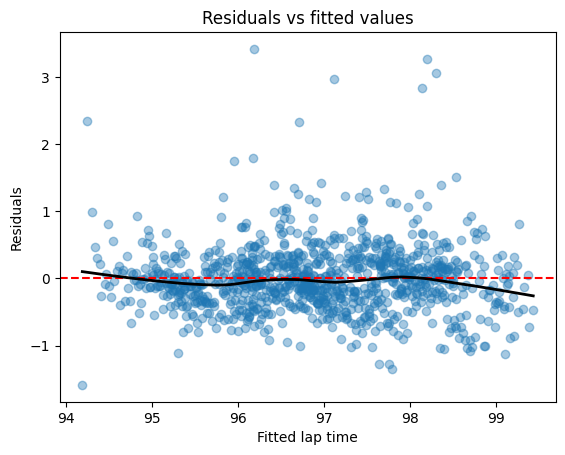

In [15]:
columns = ["lap_time_s",
    "tyre_age_laps",
    "LapNumber",
    "Stint",
    "Position"]
model_data = clean_data[columns].apply(pd.to_numeric, errors="coerce").dropna()
full_model = smf.ols(
    "lap_time_s ~ tyre_age_laps + LapNumber + Stint + Position",
    data=model_data
).fit()
fitted = full_model.fittedvalues
residuals = full_model.resid
plt.scatter(fitted, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
smooth = sm.nonparametric.lowess(residuals, fitted, frac=0.4)
plt.plot(smooth[:, 0], smooth[:, 1], color="black", linewidth=2)
plt.xlabel("Fitted lap time")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted values")
plt.show()


The Residuals vs. Fitted Values plot shows that the residuals are generally distributed around zero, which suggests that the linearity assumption is mostly satisfied. However, the red dashed line represents zero residuals, while the black smooth line shows a slight curved pattern, indicating a possible minor non-linear relationship. The spread of residuals also appears to increase slightly as fitted lap times increase, suggesting potential heteroscedasticity. Additionally, several outliers with large residuals are visible. Overall, the model appears reasonably appropriate, but further diagnostic tests for heteroscedasticity and influential observations, such as Cook’s Distance, are recommended.

The table shows the 10 most influential laps; the largest Cook’s distance is for **SAR’s lap 54 (0.0855)**, followed by **HUL’s lap 38 (0.0691)**. These laps exceed the 0.004 screening cutoff and may affect the model, so they merit review—but that alone doesn’t mean they are errors or should be removed.

In [17]:
correlation_matrix = clean_data[columns].corr()
correlation_matrix.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)

,lap_time_s,tyre_age_laps,LapNumber,Stint,Position
lap_time_s,1.000000,0.005605,-0.656982,-0.706046,0.387600
tyre_age_laps,0.005605,1.000000,0.524577,0.185859,-0.184797
LapNumber,-0.656982,0.524577,1.000000,0.899291,-0.020418
Stint,-0.706046,0.185859,0.899291,1.000000,0.170240
Position,0.387600,-0.184797,-0.020418,0.170240,1.000000


The correlation matrix shows that lap time has almost no linear correlation with tyre age (`r = 0.006`), a moderate negative correlation with lap number (`r = −0.657`) and stint (`r = −0.706`), and a moderate positive correlation with finishing position (`r = 0.388`). The strongest relationship between predictors is between lap number and stint (`r = 0.899`), suggesting they may contain overlapping information, so we should check them with VIF before deciding whether to keep both in the regression. These are pairwise associations, not causal effects; in particular, position is ordinal, and the results do not control for the other variables.

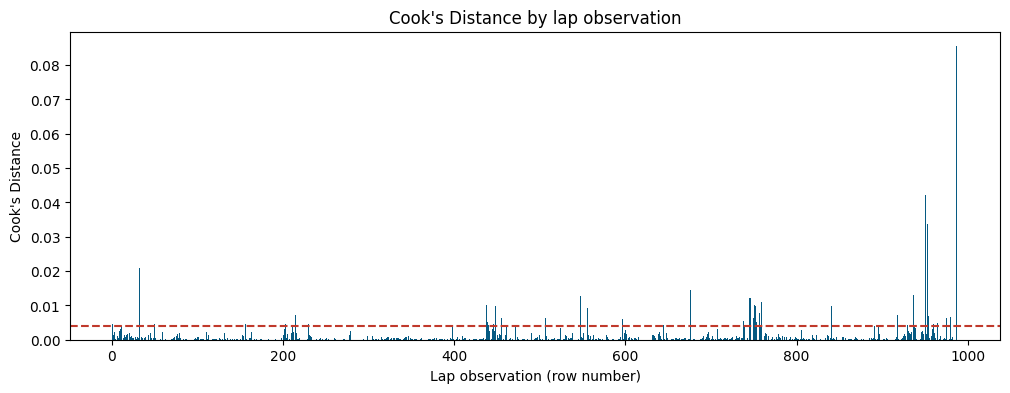

In [20]:
analysis = clean_data[columns].copy()
analysis["Driver"] = data["Driver"]
for col in columns[1:]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")
analysis = analysis.dropna().reset_index(drop=True)
full_ols = smf.ols(
    "lap_time_s ~ tyre_age_laps + LapNumber + Stint + Position",
    data=analysis
).fit()
analysis["Cooks D"] = full_ols.get_influence().cooks_distance[0]
n = len(analysis)
cook_cutoff = 4 / n
plt.figure(figsize=(12, 4))
plt.bar(
    range(1, n + 1),
    analysis["Cooks D"],
    color="#065A82")
plt.axhline(
    cook_cutoff,
    color="#C0392B",
    linestyle="--",
    label=f"Screening threshold 4/n = {cook_cutoff:.4f}")
plt.xlabel("Lap observation (row number)")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance by lap observation")
analysis = clean_data[columns].copy()
analysis["Driver"] = data["Driver"]


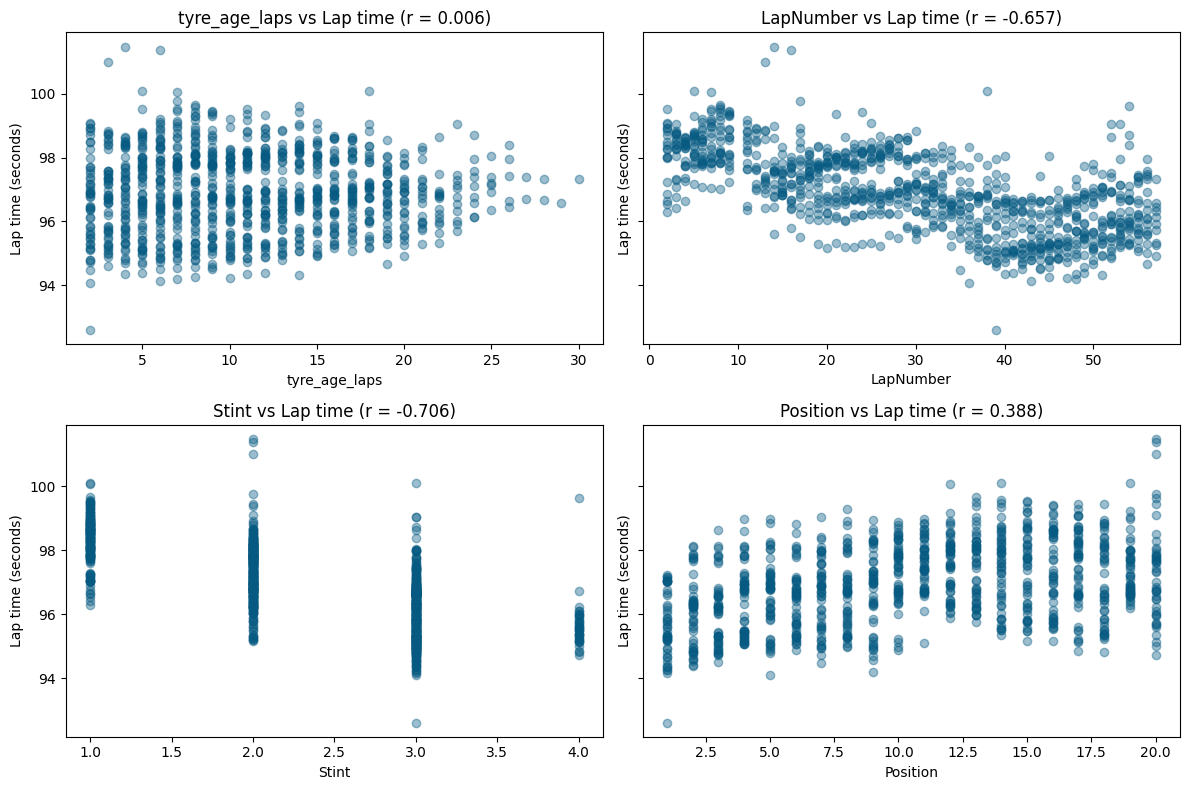

In [22]:
predictors = ["tyre_age_laps", "LapNumber", "Stint", "Position"]
plot_data = clean_data[predictors + ["lap_time_s"]].dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, col in zip(axes.flat, predictors):
    r = plot_data[col].corr(plot_data["lap_time_s"])
    ax.scatter(
        plot_data[col],
        plot_data["lap_time_s"],
        color="#065A82",
        alpha=0.4
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Lap time (seconds)")
    ax.set_title(f"{col} vs Lap time (r = {r:.3f})")
plt.tight_layout()
plt.show()


The scatter plots show almost no clear linear relationship between tyre age and lap time (r = 0.006). Lap time is negatively correlated with lap number and stint, while it is positively correlated with finishing position. However, these are unadjusted pairwise relationships and should not be interpreted as causal effects. Lap number and stint are strongly correlated with each other (r = 0.899), so their VIF values should be checked before selecting predictors for the regression model.

In [23]:
y = model_data["lap_time_s"]
X_full = model_data[["tyre_age_laps", "LapNumber", "Stint", "Position"]]
X_full_c = sm.add_constant(X_full)
model_full = sm.OLS(y, X_full_c).fit()
print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:             lap_time_s   R-squared:                       0.839
Model:                            OLS   Adj. R-squared:                  0.838
Method:                 Least Squares   F-statistic:                     1280.
Date:                Fri, 16 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:06:07   Log-Likelihood:                -726.67
No. Observations:                 988   AIC:                             1463.
Df Residuals:                     983   BIC:                             1488.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            97.5706      0.096   1012.101

Using 988 lap observations, the multiple regression model had an R² of 0.839 and an adjusted R² of 0.838. All four predictors were statistically significant in this model (p < 0.001).

In [25]:
predictors = [
    "tyre_age_laps",
    "LapNumber",
    "Stint",
    "Position"]
check = clean_data[["lap_time_s"] + predictors].copy()
for column in ["lap_time_s"] + predictors:
    check[column] = pd.to_numeric(check[column], errors="coerce")
check = check.dropna()
X = sm.add_constant(check[predictors])
vif = pd.DataFrame({
    "Predictor": predictors,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(1, X.shape[1])]})
print("VIF numbers:", len(check))
display(vif.round(2))


VIF numbers: 988


,Predictor,VIF
0,tyre_age_laps,3.53
1,LapNumber,20.21
2,Stint,15.75
3,Position,1.29


We used VIF to guide predictor selection, rather than reporting it as a formality. LapNumber had a VIF of 20.21 and Stint had a VIF of 15.75, indicating substantial overlap with the other predictors. Tyre age had a VIF of 3.53, while Position had a VIF of 1.29. Because our research focuses on tyre degradation and LapNumber helps account for race progress, we will retain LapNumber and remove Stint in the next model, then compare the model fit using R², adjusted R², AIC, and BIC.

In [28]:
r_lap_stint = clean_data["LapNumber"].corr(clean_data["Stint"])
vif_simple = 1 / (1 - r_lap_stint**2)

print(f"corr(LapNumber, Stint) = {r_lap_stint:.4f}")
print(f"Simple VIF             = {vif_simple:.3f}")


corr(LapNumber, Stint) = 0.8993
Simple VIF             = 5.228


Lap number and stint number were strongly correlated (r = 0.899). Their pairwise VIF was 5.228, suggesting that they may provide overlapping information

Lap number and stint number were selected for an initial multicollinearity check because they had the strongest pairwise correlation among the candidate predictors (Pearson’s r = 0.899). This high correlation suggests that they may contain overlapping information, which could make it difficult to distinguish their individual effects in a regression model. Although they represent different concepts—race progress and the current tyre run—we therefore examined their VIF before deciding whether to include both.

In [29]:
reduced_model = smf.ols(
    "lap_time_s ~ tyre_age_laps + LapNumber + Position",
    data=model_data
).fit()
comparison = pd.DataFrame({
    "Model": ["Full model", "Model without Stint"],
    "R²": [full_model.rsquared, reduced_model.rsquared],
    "Adjusted R²": [full_model.rsquared_adj, reduced_model.rsquared_adj],
    "AIC": [full_model.aic, reduced_model.aic],
    "BIC": [full_model.bic, reduced_model.bic]
})
print("Observations in each model:", len(model_data))
display(comparison.round(3))

Observations in each model: 988


,Model,R²,Adjusted R²,AIC,BIC
0,Full model,0.839,0.838,1463.344,1487.822
1,Model without Stint,0.820,0.820,1569.939,1589.522


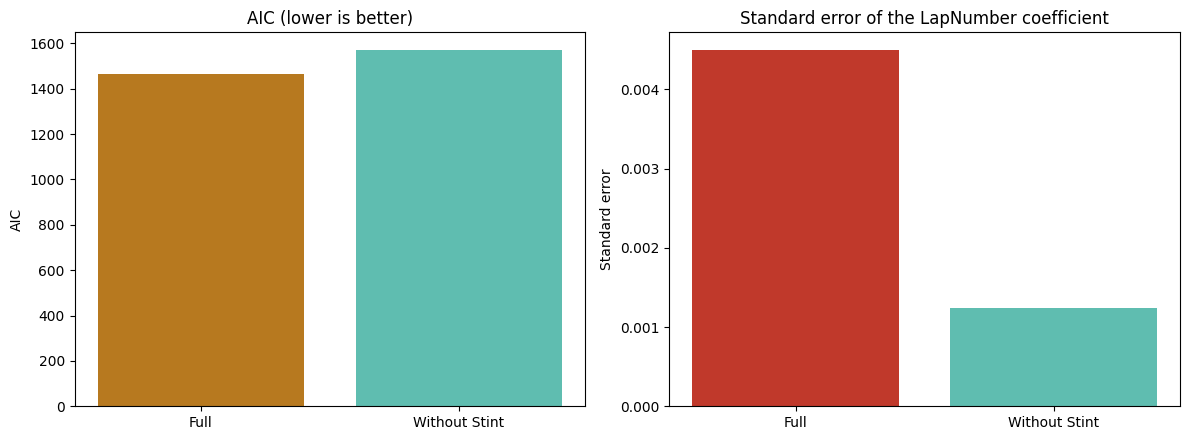

AIC: full = 1463.344, without Stint = 1569.939
SE(LapNumber): full = 0.0045, without Stint = 0.0012
Change in SE after removing Stint: -72.3%


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(
    ["Full", "Without Stint"],
    [full_model.aic, reduced_model.aic],
    color=["#B7791F", "#5FBDB0"]
)
axes[0].set_title("AIC (lower is better)")
axes[0].set_ylabel("AIC")
axes[1].bar(
    ["Full", "Without Stint"],
    [full_model.bse["LapNumber"], reduced_model.bse["LapNumber"]],
    color=["#C0392B", "#5FBDB0"]
)
axes[1].set_title("Standard error of the LapNumber coefficient")
axes[1].set_ylabel("Standard error")
plt.tight_layout()
plt.show()
se_full = full_model.bse["LapNumber"]
se_reduced = reduced_model.bse["LapNumber"]
change = 100 * (se_reduced / se_full - 1)
print(f"AIC: full = {full_model.aic:.3f}, without Stint = {reduced_model.aic:.3f}")
print(f"SE(LapNumber): full = {se_full:.4f}, without Stint = {se_reduced:.4f}")
print(f"Change in SE after removing Stint: {change:+.1f}%")


The full model performed better than the model without Stint: R² and adjusted R² were higher, while AIC and BIC were lower. This suggests that Stint contributes useful information to the model. However, its high VIF indicates substantial overlap with LapNumber, so we will also test a model that retains Stint but excludes LapNumber before making a final predictor-selection decision.

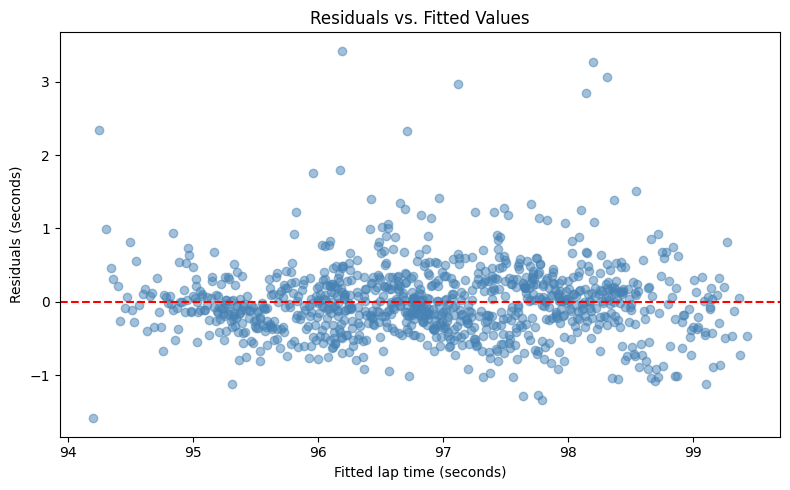

In [31]:
fitted = full_model.fittedvalues
residuals = full_model.resid
plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, alpha=0.5, color="steelblue")
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Fitted lap time (seconds)")
plt.ylabel("Residuals (seconds)")
plt.title("Residuals vs. Fitted Values")
plt.tight_layout()
plt.show()


In [32]:
from statsmodels.stats.diagnostic import het_breuschpagan
result = het_breuschpagan(full_model.resid, full_model.model.exog)
print("LM statistic:", result[0])
print("LM test p-value:", result[1])
print("F-statistic:", result[2])
print("F-test p-value:", result[3])


LM statistic: 25.70616303494501
LM test p-value: 3.6268033759353134e-05
F-statistic: 6.56482388556247
F-test p-value: 3.252376538133585e-05


The Breusch–Pagan test examines whether the regression errors have constant variance. Its null hypothesis is homoscedasticity (constant error variance), while the alternative is heteroscedasticity (non-constant variance). The LM version of the test produced a statistic of 25.706 (p = 3.63 × 10⁻⁵), and the F version produced a statistic of 6.565 (p = 3.25 × 10⁻⁵). Both p-values are below 0.05, so we reject the null hypothesis and find evidence of heteroscedasticity. The LM and F statistics are two forms of the same diagnostic test, not separate findings; their statistic values do not measure the size of the heteroscedasticity. Because the error variance may not be constant, we should use heteroscedasticity-robust standard errors, such as HC3, when making inferences about the regression coefficients.

In [33]:
influence = full_model.get_influence()
influence_data = model_data.copy()
influence_data["leverage"] = influence.hat_matrix_diag
influence_data["cooks_d"] = influence.cooks_distance[0]
n = int(full_model.nobs)
p = full_model.model.exog.shape[1]
leverage_cutoff = 2 * p / n
cooks_cutoff = 4 / n
print(f"leverage: {leverage_cutoff:.4f}")
print(f"threshold Cook's Distance: {cooks_cutoff:.4f}")
print("laps higher than threshold leverage:",
      (influence_data["leverage"] > leverage_cutoff).sum())
print("laps higher than threshold Cook's Distance:",
      (influence_data["cooks_d"] > cooks_cutoff).sum())
display(
    influence_data.nlargest(10, "cooks_d")[
        ["lap_time_s", "tyre_age_laps", "LapNumber",
         "Stint", "Position", "leverage", "cooks_d"]
    ].round(4))

leverage: 0.0101
threshold Cook's Distance: 0.0040
laps higher than threshold leverage: 47
laps higher than threshold Cook's Distance: 60


,lap_time_s,tyre_age_laps,LapNumber,Stint,Position,leverage,cooks_d
1127,99.614,14.0,54.0,4.0,20.0,0.0092,0.0855
887,100.083,18.0,38.0,3.0,14.0,0.0099,0.0691
39,96.589,3.0,40.0,3.0,1.0,0.0098,0.0426
1087,101.470,4.0,14.0,2.0,20.0,0.0050,0.0420
1086,100.989,3.0,13.0,2.0,20.0,0.0053,0.0337
1089,101.370,6.0,16.0,2.0,20.0,0.0046,0.0337
789,99.042,18.0,52.0,3.0,14.0,0.0053,0.0225
38,92.608,2.0,39.0,3.0,1.0,0.0104,0.0209
773,97.706,2.0,36.0,3.0,15.0,0.0060,0.0145
1070,99.035,23.0,53.0,3.0,19.0,0.0093,0.0131


In [34]:
from statsmodels.stats.stattools import durbin_watson
dw_data = data.loc[full_model.resid.index, ["Driver", "LapNumber"]].copy()
dw_data["residual"] = full_model.resid.to_numpy()
results = []
for driver, group in dw_data.groupby("Driver"):
    group = group.sort_values("LapNumber")
    if len(group) >= 3:
        results.append({
            "Driver": driver,
            "Laps": len(group),
            "Durbin–Watson": durbin_watson(group["residual"])})
dw_table = pd.DataFrame(results)
display(dw_table.round(3))


,Driver,Laps,Durbin–Watson
0,ALB,48,0.634
1,ALO,51,1.205
2,BOT,50,1.388
3,GAS,47,1.156
4,HAM,49,0.605
5,HUL,48,0.911
6,LEC,50,0.989
7,MAG,50,0.958
8,NOR,48,1.817
9,OCO,51,1.732


The Durbin–Watson statistics were below 2 for all 20 drivers, ranging from 0.605 to 1.817. This suggests positive autocorrelation in residuals across consecutive laps, so the OLS independence assumption may be violated. Therefore, conventional standard errors and p-values should be interpreted cautiously.

In [35]:
race_order = (
    data.sort_values(["Driver", "LapNumber"])
        .groupby("Driver")
        .tail(1)
        .sort_values("Position"))
display(race_order[["Position", "Driver", "LapNumber"]])


,Position,Driver,LapNumber
56,1.0,VER,57.0
113,2.0,PER,57.0
170,3.0,SAI,57.0
227,4.0,LEC,57.0
284,5.0,RUS,57.0
341,6.0,NOR,57.0
398,7.0,HAM,57.0
455,8.0,PIA,57.0
512,9.0,ALO,57.0
569,10.0,STR,57.0


In [36]:
for col in columns[1:]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")
analysis = analysis.dropna().reset_index(drop=True)
model = smf.ols(
    "lap_time_s ~ tyre_age_laps + LapNumber + Stint + Position",
    data=analysis
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": analysis["Driver"],
        "use_correction": True,
        "df_correction": True},
    use_t=True)
b = model.params
print(
    f"lap_time_s = {b['Intercept']:.4f}"
    f" {b['tyre_age_laps']:+.4f} × tyre_age_laps"
    f" {b['LapNumber']:+.4f} × LapNumber"
    f" {b['Stint']:+.4f} × Stint"
    f" {b['Position']:+.4f} × Position"
)
results = pd.DataFrame({
    "Coefficient": model.params,
    "Cluster SE": model.bse,
    "p-value": model.pvalues,
    "95% CI lower": model.conf_int()[0],
    "95% CI upper": model.conf_int()[1]
})

display(results.round(4))


lap_time_s = 97.5706 +0.0837 × tyre_age_laps -0.0287 × LapNumber -0.8483 × Stint +0.1197 × Position


,Coefficient,Cluster SE,p-value,95% CI lower,95% CI upper
Intercept,97.5706,0.2641,0.0000,97.0179,98.1234
tyre_age_laps,0.0837,0.0143,0.0000,0.0538,0.1135
LapNumber,-0.0287,0.0146,0.0644,-0.0593,0.0019
Stint,-0.8483,0.2413,0.0023,-1.3533,-0.3433
Position,0.1197,0.0083,0.0000,0.1023,0.1371
